  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

After preprocessing: (397884, 9)

Customer-level data:
   CustomerID  Total_Spending  Total_Quantity  Number_of_Transactions  \
0     12346.0        77183.60           74215                       1   
1     12347

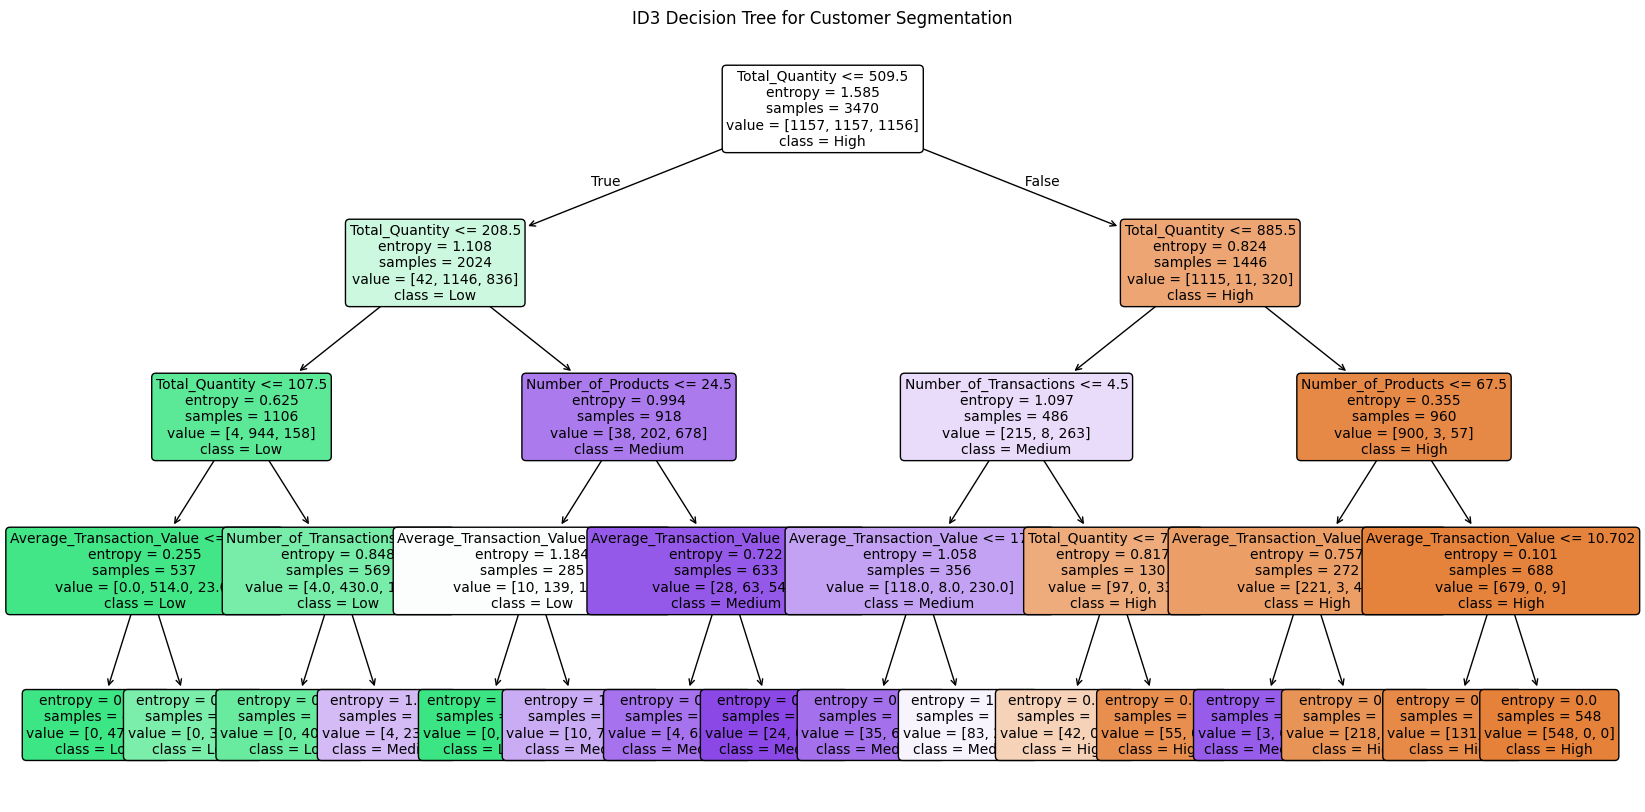


FEATURE IMPORTANCE
                     Feature  Importance
0             Total_Quantity    0.851269
3  Average_Transaction_Value    0.072278
2         Number_of_Products    0.050347
1     Number_of_Transactions    0.026105


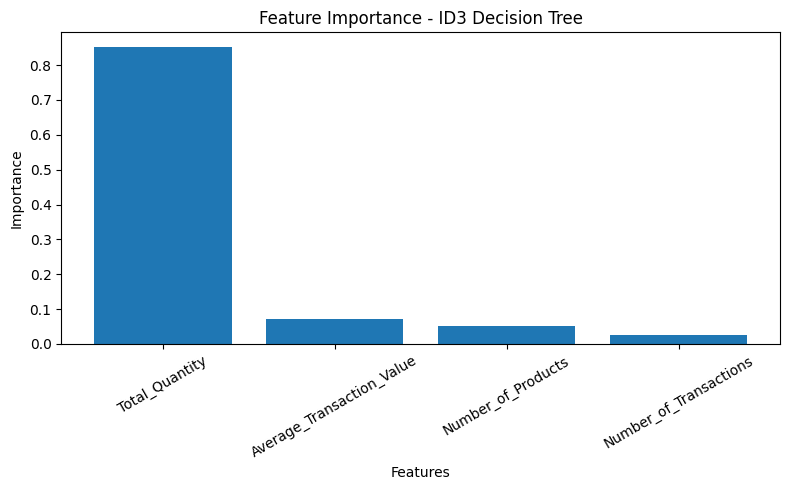


CUSTOMER SEGMENT ANALYSIS
         Total_Quantity  Number_of_Transactions  Number_of_Products  \
Segment                                                               
Low          142.633472                1.325035           18.644537   
Medium       433.367911                2.573997           46.256570   
High        2997.865837                8.917012          119.602351   

         Average_Transaction_Value  
Segment                             
Low                      21.762259  
Medium                   28.561596  
High                    154.727662  


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
df=pd.read_csv("online-retail-dataset.csv")

print("=========================================================================")
print(df.head())
print("=========================================================================")

# ============================================================
# 3. Data preprocessing
# ============================================================

# Remove rows where CustomerID is missing
df = df.dropna(subset=["CustomerID"])

# Remove cancelled transactions
# In this dataset, InvoiceNo beginning with 'C' indicates cancellation
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid quantities and prices
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

# Create total amount spent for each transaction
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("\nAfter preprocessing:", df.shape)


# ============================================================
# 4. Create customer-level features
# ============================================================

customer_data = df.groupby("CustomerID").agg(
    Total_Spending=("TotalAmount", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Number_of_Transactions=("InvoiceNo", "nunique"),
    Number_of_Products=("StockCode", "nunique"),
    Average_Transaction_Value=("TotalAmount", "mean")
).reset_index()

print("\nCustomer-level data:")
print("=========================================================================")
print(customer_data.head())
print("=========================================================================")

# ============================================================
# 5. Create customer segments
# ============================================================

# Divide customers into 3 groups based on spending.
# qcut creates approximately equal-sized groups.

customer_data["Segment"] = pd.qcut(
    customer_data["Total_Spending"],
    q=3,
    labels=["Low", "Medium", "High"]
)

print("\nCustomer segment distribution:")
print("=========================================================================")
print(customer_data["Segment"].value_counts())
print("=========================================================================")


# ============================================================
# 6. Prepare X and y
# ============================================================

# IMPORTANT:
# We exclude Total_Spending because Segment was created
# directly from Total_Spending.
#
# Otherwise, the model would simply learn:
# Total_Spending -> Segment
#
# This would cause target leakage.

features = [
    "Total_Quantity",
    "Number_of_Transactions",
    "Number_of_Products",
    "Average_Transaction_Value"
]

X = customer_data[features]
y = customer_data["Segment"]


# Convert categorical labels into numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


# ============================================================
# 7. Train-test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)


# ============================================================
# 8. Implement ID3 Decision Tree
# ============================================================

# In sklearn, criterion="entropy" gives an ID3-style
# decision tree based on information gain.

id3_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)

id3_model.fit(X_train, y_train)


# ============================================================
# 9. Make predictions
# ============================================================

y_pred = id3_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\n======================================")
print("MODEL PERFORMANCE")
print("======================================")

print("Accuracy:", accuracy)
print("=========================================================================")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)
print("=========================================================================")

# ============================================================
# 10. Visualize the Decision Tree
# ============================================================

plt.figure(figsize=(20, 10))

plot_tree(
    id3_model,
    feature_names=features,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("ID3 Decision Tree for Customer Segmentation")
plt.show()


# ============================================================
# 11. Feature Importance
# ============================================================

importance = pd.DataFrame({
    "Feature": features,
    "Importance": id3_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n======================================")
print("FEATURE IMPORTANCE")
print("======================================")
print("=========================================================================")
print(importance)
print("=========================================================================")

# ============================================================
# 12. Plot Feature Importance
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance - ID3 Decision Tree")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


# ============================================================
# 13. Display tree rules
# ============================================================

# from sklearn.tree import export_text

# tree_rules = export_text(
#     id3_model,
#     feature_names=features
# )

# print("\n======================================")
# print("DECISION TREE RULES")
# print("======================================")

# print(tree_rules)


# ============================================================
# 13 . Analyze customer segments
# ============================================================

print("\n======================================")
print("CUSTOMER SEGMENT ANALYSIS")
print("======================================")

segment_summary = customer_data.groupby("Segment", observed=True)[
    features
].mean()
print("=========================================================================")
print(segment_summary)
print("=========================================================================")

